# Exploratory Data Analysis — Professor Research Dataset

This notebook performs a thorough EDA of the professors dataset including:
- Data overview & missing value handling
- Univariate analysis (numerical & categorical)
- Bivariate analysis
- Multivariate analysis
- Correlation matrix
- Feature engineering

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

print('Libraries loaded successfully.')

Libraries loaded successfully.


## 1. Data Loading & Overview

In [3]:
df = pd.read_csv('../dataset/professors.csv')
print(f'Dataset shape: {df.shape}')
print(f'Rows: {df.shape[0]}, Columns: {df.shape[1]}')
df.head(10)

Dataset shape: (317, 26)
Rows: 317, Columns: 26


,Professor,University,Rank,rank_place,Research area,OpenAlex_Author_ID,Author_Status,Matched_Institution,Venues,Number_of_Top_Venue_Papers,...,AAAI,IJCAI,CVPR,ICCV,ECCV,ACL,EMNLP,NAACL,profile_url,Email
0,Xiaowei Jia,University of Pittsburgh,r1,67,Other,A5001445783,MATCHED,University of Pittsburgh,AAAI,10,...,12,0,0,0,0,0,0,0,NaN,NaN
1,Vincent Conitzer,Carnegie Mellon University,r1,24,Artificial Intelligence,A5050903632,MATCHED,Carnegie Mellon University,AAAI,9,...,22,0,0,0,0,0,0,0,https://csd.cmu.edu/people/faculty/vincent-con...,c@cmu.edu
2,Alan Fern,Oregon State University,r1,142,Artificial Intelligence,A5030052689,MATCHED,Oregon State University,AAAI,8,...,12,0,0,0,0,0,0,0,NaN,NaN
3,Kuldeep S. Meel,Georgia Institute of Technology (Georgia Tech),r1,33,Artificial Intelligence,A5041528950,MATCHED,Georgia Institute of Technology,AAAI,8,...,16,0,0,0,0,0,0,0,https://scs.gatech.edu/people/kuldeep-s-meel,NaN
4,Tianlong Chen,University of North Carolina at Chapel Hill,r1,22,Machine Learning,A5103073431,MATCHED,University of North Carolina at Chapel Hill,AAAI,8,...,8,0,3,0,0,0,0,0,NaN,NaN
5,Tuomas Sandholm,Carnegie Mellon University,r1,24,Machine Learning,A5136279299,MATCHED,Carnegie Mellon University,AAAI,8,...,0,0,0,0,0,0,0,0,https://csd.cmu.edu/people/faculty/tuomas-sand...,sandholm@cs.cmu.edu
6,Meiyi Ma,Vanderbilt University,r1,18,Other,A5007967134,MATCHED,Vanderbilt University,AAAI,6,...,4,0,0,0,0,0,0,0,NaN,NaN
7,Percy Liang,Stanford University,r1,3,Machine Learning,A5025255782,MATCHED,Stanford University,AAAI;ACL,6,...,4,0,0,0,0,3,3,0,https://www.cs.stanford.edu/people/percy-liang,NaN
8,Peter Stone,University of Texas at Austin,r1,32,Machine Learning,A5001594330,MATCHED,The University of Texas at Austin,AAAI,6,...,12,0,1,0,0,0,0,0,https://www.cs.utexas.edu/people/faculty-resea...,NaN
9,Yexiang Xue,Purdue University,r1,43,Reinforcement Learning,A5060838579,MATCHED,Purdue University West Lafayette,AAAI,6,...,8,0,0,0,0,0,0,0,https://www.cs.purdue.edu/people/faculty/yexia...,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 317 entries, 0 to 316
Data columns (total 26 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Professor                   317 non-null    str    
 1   University                  317 non-null    str    
 2   Rank                        317 non-null    str    
 3   rank_place                  317 non-null    int64  
 4   Research area               317 non-null    str    
 5   OpenAlex_Author_ID          317 non-null    str    
 6   Author_Status               317 non-null    str    
 7   Matched_Institution         311 non-null    str    
 8   Venues                      317 non-null    str    
 9   Number_of_Top_Venue_Papers  317 non-null    int64  
 10  Years                       317 non-null    str    
 11  h_index                     306 non-null    float64
 12  total_citations             306 non-null    float64
 13  NeurIPS                     317 non-null    in

In [5]:
df.describe()

,rank_place,Number_of_Top_Venue_Papers,h_index,total_citations,NeurIPS,ICML,ICLR,AAAI,IJCAI,CVPR,ICCV,ECCV,ACL,EMNLP,NAACL
count,317.000000,317.000000,306.000000,306.000000,317.000000,317.000000,317.000000,317.000000,317.0,317.000000,317.000000,317.0,317.000000,317.000000,317.0
mean,41.220820,1.845426,37.352941,11095.006536,0.242902,0.119874,0.082019,2.703470,0.0,0.255521,0.132492,0.0,0.548896,0.126183,0.0
std,50.479114,1.455485,27.788775,17048.983977,0.784132,0.495054,0.346170,3.056497,0.0,1.016171,0.485340,0.0,1.989285,0.524563,0.0
min,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0
25%,15.000000,1.000000,16.250000,1315.750000,0.000000,0.000000,0.000000,1.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0
50%,33.000000,1.000000,31.000000,4815.000000,0.000000,0.000000,0.000000,2.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0
75%,46.000000,2.000000,53.000000,13518.000000,0.000000,0.000000,0.000000,3.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0
max,352.000000,10.000000,148.000000,113323.000000,7.000000,5.000000,3.000000,22.000000,0.0,12.000000,3.000000,0.0,16.000000,4.000000,0.0


In [6]:
df.describe(include='object')

,Professor,University,Rank,Research area,OpenAlex_Author_ID,Author_Status,Matched_Institution,Venues,Years,profile_url,Email
count,317,317,317,317,317,317,311,317,317,203,103
unique,317,45,2,10,317,1,50,4,7,203,102
top,Xiaowei Jia,University of Illinois Urbana-Champaign,r1,Machine Learning,A5001445783,MATCHED,University of Illinois Urbana-Champaign,AAAI,2024,https://csd.cmu.edu/people/faculty/vincent-con...,jiaqima@illinois.edu
freq,1,31,310,131,1,317,30,293,95,1,2


## 2. Missing Value Analysis

In [7]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Count': missing, 'Percentage': missing_pct})
missing_df = missing_df[missing_df['Count'] > 0].sort_values('Percentage', ascending=False)
print('Columns with missing values:')
missing_df

Columns with missing values:


,Count,Percentage
Email,214,67.507886
profile_url,114,35.962145
total_citations,11,3.470032
h_index,11,3.470032
Matched_Institution,6,1.892744


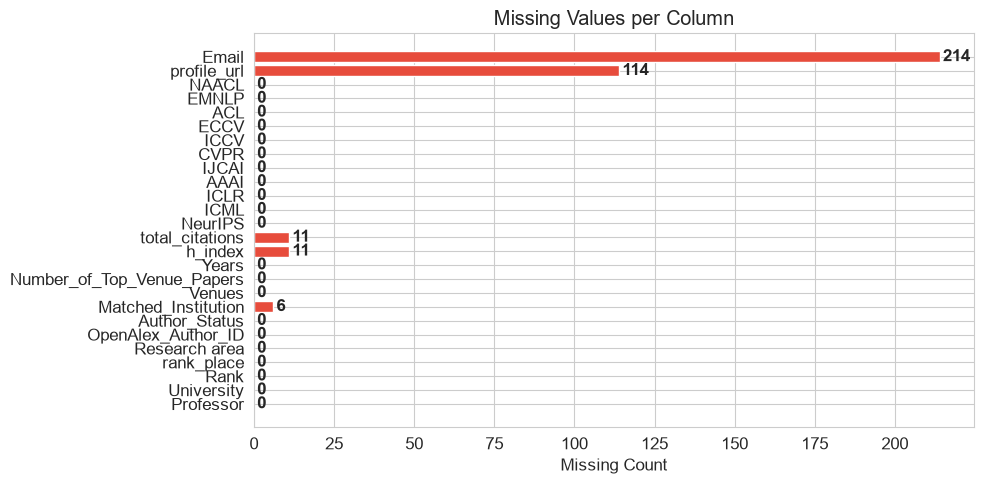

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in missing.values]
ax.barh(missing.index, missing.values, color=colors)
ax.set_xlabel('Missing Count')
ax.set_title('Missing Values per Column')
for i, v in enumerate(missing.values):
    ax.text(v + 1, i, str(v), va='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [10]:
# Replace all missing values with keyword 'missing'
df.fillna('missing', inplace=True)
print('Missing values after replacement:')
print(df.isnull().sum().sum(), 'remaining')
df.head()

TypeError: Invalid value 'missing' for dtype 'float64'

## 3. Univariate Analysis

### 3.1 Numerical Columns

In [11]:
num_cols = ['rank_place', 'Number_of_Top_Venue_Papers', 'h_index', 'total_citations',
            'NeurIPS', 'ICML', 'ICLR', 'AAAI', 'IJCAI', 'CVPR', 'ICCV', 'ECCV', 'ACL', 'EMNLP', 'NAACL']

# Convert h_index and total_citations to numeric (they have 'missing' strings)
for col in ['h_index', 'total_citations']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
rank_place,317.0,41.220820,50.479114,1.0,15.00,33.0,46.0,352.0
Number_of_Top_Venue_Papers,317.0,1.845426,1.455485,1.0,1.00,1.0,2.0,10.0
h_index,306.0,37.352941,27.788775,1.0,16.25,31.0,53.0,148.0
total_citations,306.0,11095.006536,17048.983977,1.0,1315.75,4815.0,13518.0,113323.0
NeurIPS,317.0,0.242902,0.784132,0.0,0.00,0.0,0.0,7.0
ICML,317.0,0.119874,0.495054,0.0,0.00,0.0,0.0,5.0
ICLR,317.0,0.082019,0.346170,0.0,0.00,0.0,0.0,3.0
AAAI,317.0,2.703470,3.056497,0.0,1.00,2.0,3.0,22.0
IJCAI,317.0,0.000000,0.000000,0.0,0.00,0.0,0.0,0.0
CVPR,317.0,0.255521,1.016171,0.0,0.00,0.0,0.0,12.0


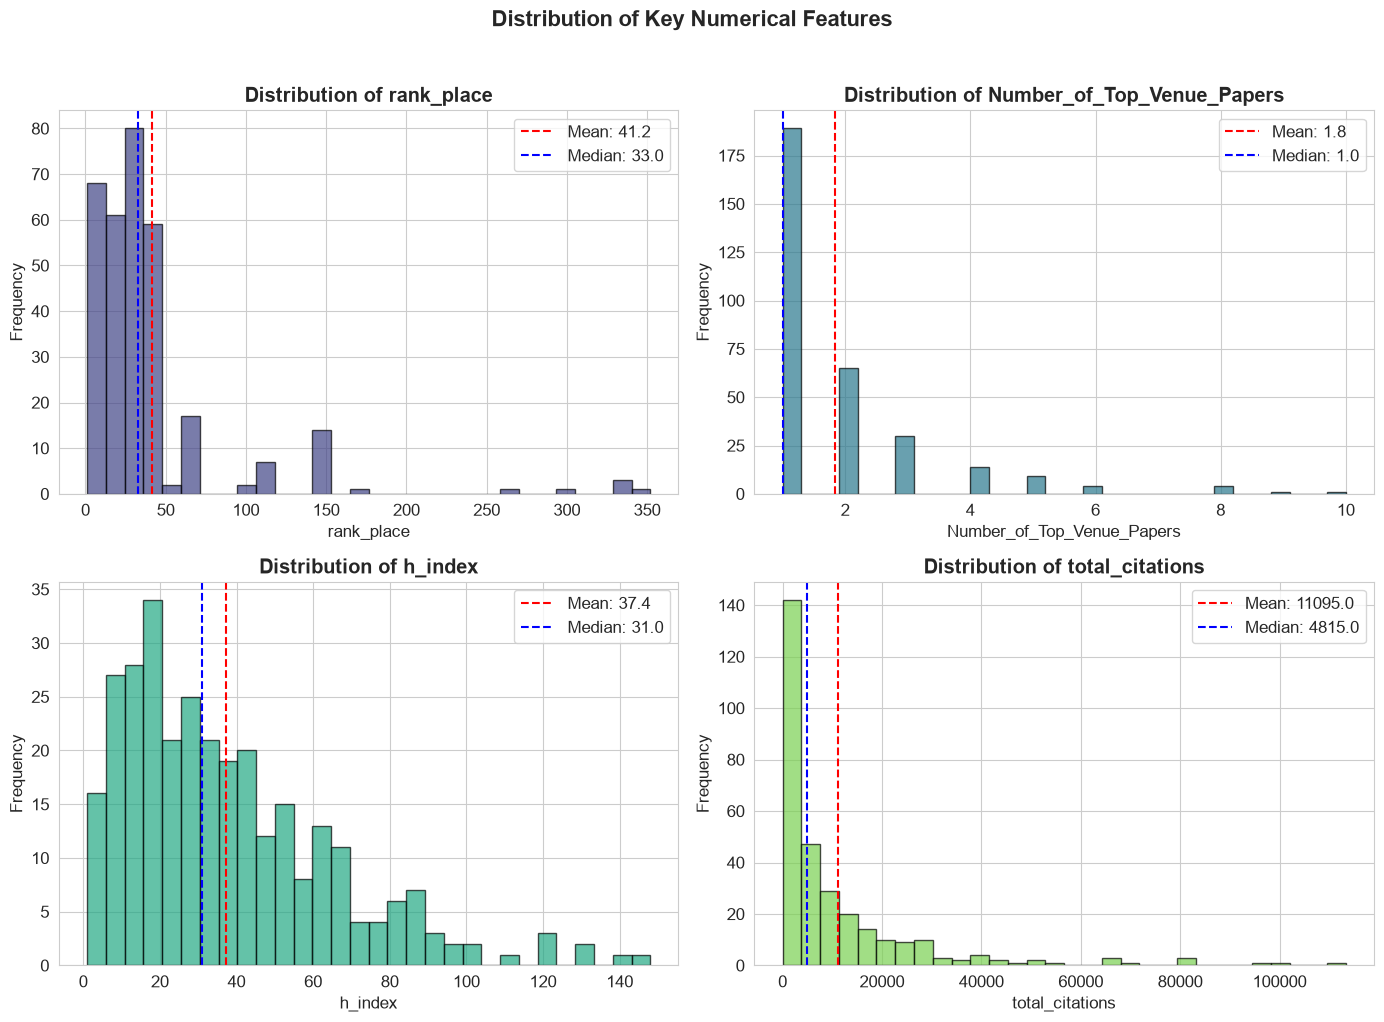

In [12]:
# Distribution plots for key numerical columns
key_num = ['rank_place', 'Number_of_Top_Venue_Papers', 'h_index', 'total_citations']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for i, col in enumerate(key_num):
    ax = axes[i // 2][i % 2]
    data = pd.to_numeric(df[col], errors='coerce').dropna()
    ax.hist(data, bins=30, color=sns.color_palette('viridis', 4)[i], edgecolor='black', alpha=0.7)
    ax.set_title(f'Distribution of {col}', fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.axvline(data.mean(), color='red', linestyle='--', label=f'Mean: {data.mean():.1f}')
    ax.axvline(data.median(), color='blue', linestyle='--', label=f'Median: {data.median():.1f}')
    ax.legend()
plt.suptitle('Distribution of Key Numerical Features', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

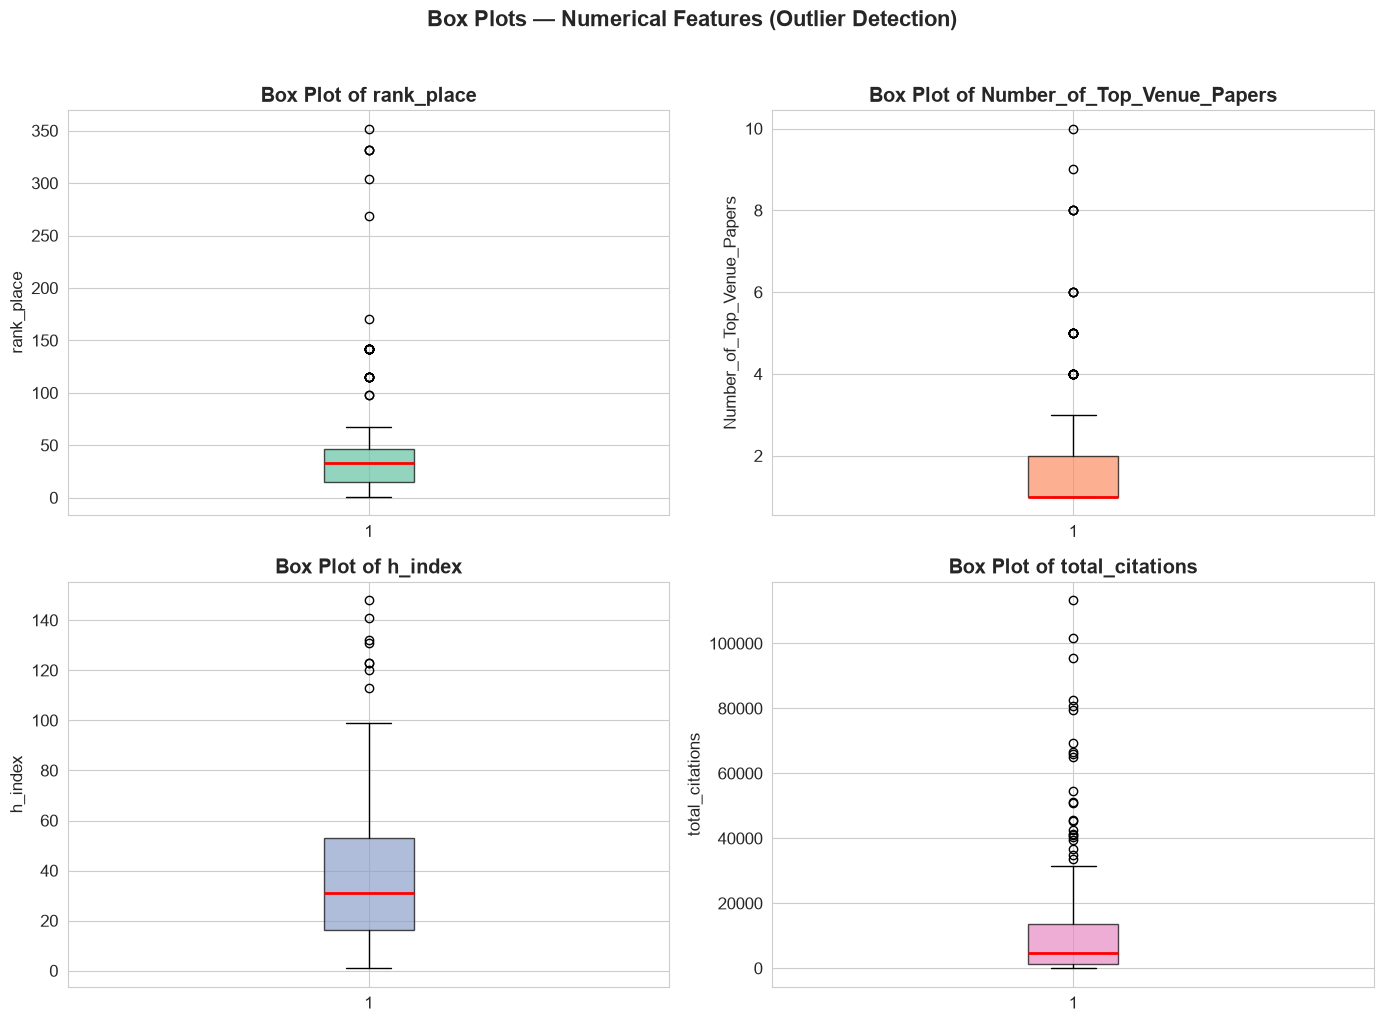

In [13]:
# Box plots for numerical columns
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for i, col in enumerate(key_num):
    ax = axes[i // 2][i % 2]
    data = pd.to_numeric(df[col], errors='coerce').dropna()
    bp = ax.boxplot(data, patch_artist=True,
                    boxprops=dict(facecolor=sns.color_palette('Set2', 4)[i], alpha=0.7),
                    medianprops=dict(color='red', linewidth=2))
    ax.set_title(f'Box Plot of {col}', fontweight='bold')
    ax.set_ylabel(col)
plt.suptitle('Box Plots — Numerical Features (Outlier Detection)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

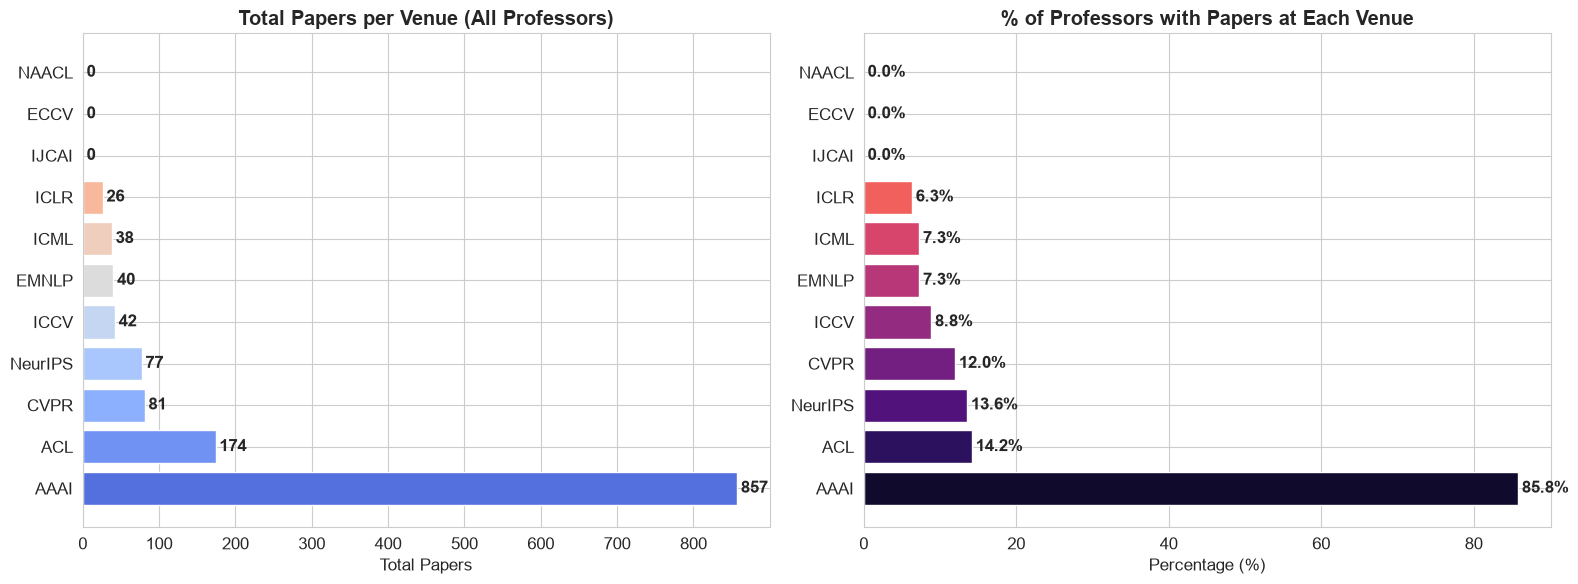

In [14]:
# Venue paper counts distribution
venue_cols = ['NeurIPS', 'ICML', 'ICLR', 'AAAI', 'IJCAI', 'CVPR', 'ICCV', 'ECCV', 'ACL', 'EMNLP', 'NAACL']
venue_totals = df[venue_cols].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Total papers per venue
bars = axes[0].barh(venue_totals.index, venue_totals.values, color=sns.color_palette('coolwarm', len(venue_cols)))
axes[0].set_title('Total Papers per Venue (All Professors)', fontweight='bold')
axes[0].set_xlabel('Total Papers')
for bar, val in zip(bars, venue_totals.values):
    axes[0].text(val + 5, bar.get_y() + bar.get_height()/2, str(val), va='center', fontweight='bold')

# Venues with at least 1 paper — proportion of professors
venue_profs = (df[venue_cols] > 0).sum().sort_values(ascending=False)
venue_profs_pct = (venue_profs / len(df)) * 100
bars2 = axes[1].barh(venue_profs_pct.index, venue_profs_pct.values, color=sns.color_palette('magma', len(venue_cols)))
axes[1].set_title('% of Professors with Papers at Each Venue', fontweight='bold')
axes[1].set_xlabel('Percentage (%)')
for bar, val in zip(bars2, venue_profs_pct.values):
    axes[1].text(val + 0.5, bar.get_y() + bar.get_height()/2, f'{val:.1f}%', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

### 3.2 Categorical Columns

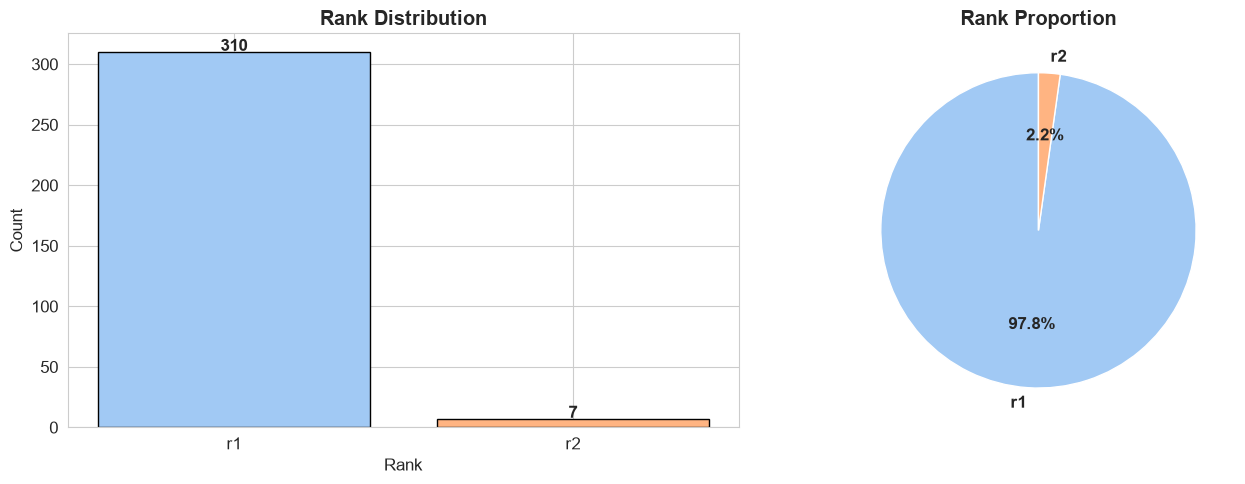

In [15]:
# Rank distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rank_counts = df['Rank'].value_counts()
colors_rank = sns.color_palette('pastel', len(rank_counts))
axes[0].bar(rank_counts.index, rank_counts.values, color=colors_rank, edgecolor='black')
axes[0].set_title('Rank Distribution', fontweight='bold')
axes[0].set_xlabel('Rank')
axes[0].set_ylabel('Count')
for i, v in enumerate(rank_counts.values):
    axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold')

# Pie chart
axes[1].pie(rank_counts.values, labels=rank_counts.index, autopct='%1.1f%%',
            colors=colors_rank, startangle=90, textprops={'fontweight': 'bold'})
axes[1].set_title('Rank Proportion', fontweight='bold')

plt.tight_layout()
plt.show()

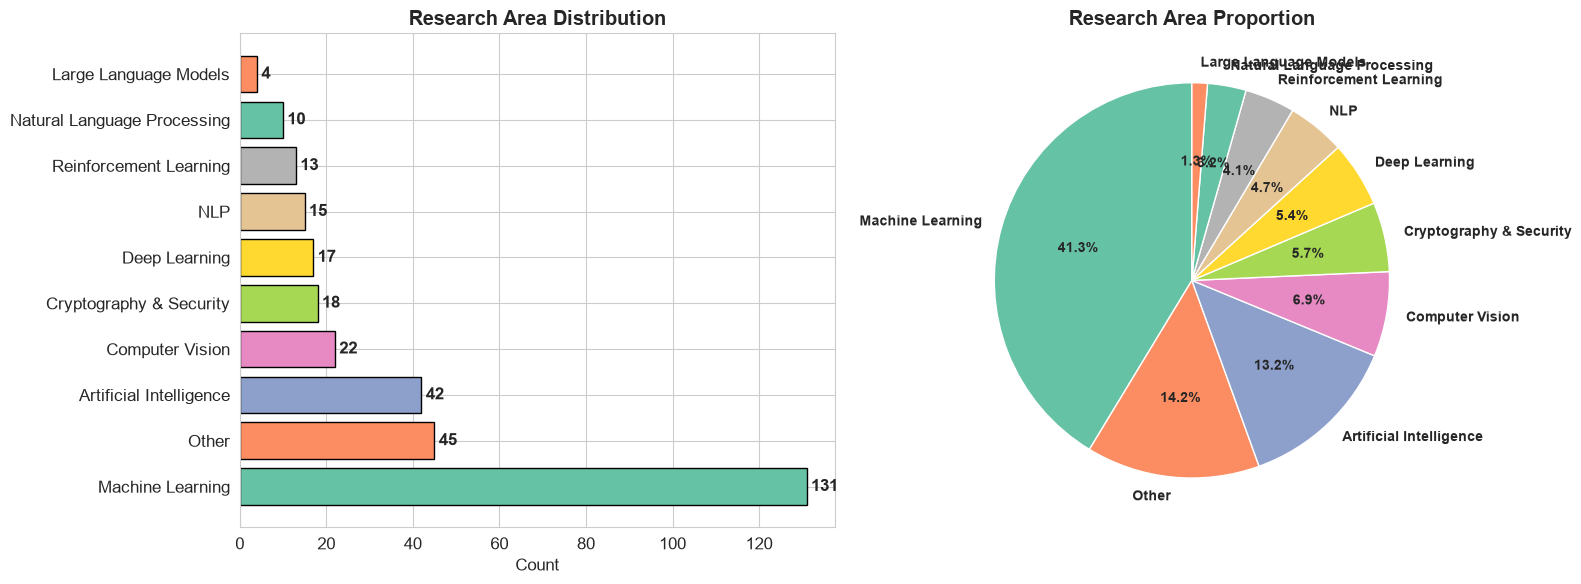

In [16]:
# Research area distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ra_counts = df['Research area'].value_counts()
colors_ra = sns.color_palette('Set2', len(ra_counts))
axes[0].barh(ra_counts.index, ra_counts.values, color=colors_ra, edgecolor='black')
axes[0].set_title('Research Area Distribution', fontweight='bold')
axes[0].set_xlabel('Count')
for i, v in enumerate(ra_counts.values):
    axes[0].text(v + 1, i, str(v), va='center', fontweight='bold')

axes[1].pie(ra_counts.values, labels=ra_counts.index, autopct='%1.1f%%',
            colors=colors_ra, startangle=90, textprops={'fontweight': 'bold', 'fontsize': 10})
axes[1].set_title('Research Area Proportion', fontweight='bold')

plt.tight_layout()
plt.show()

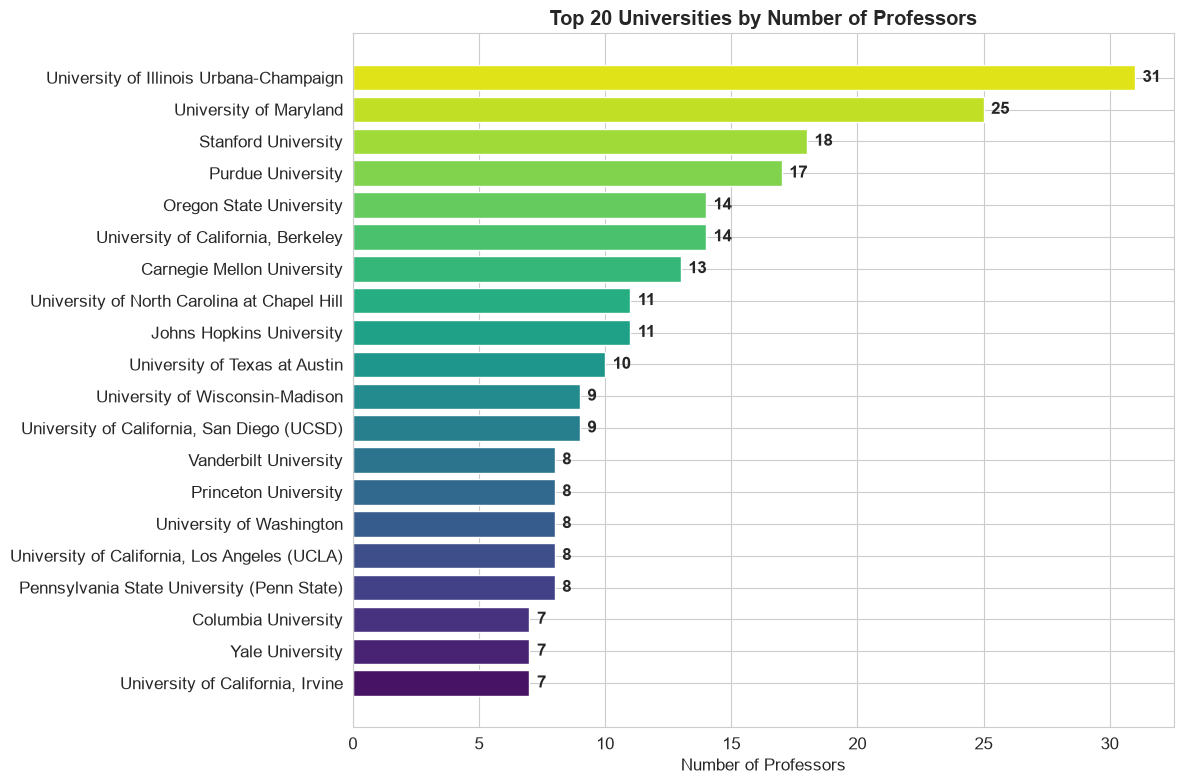

In [17]:
# Top 20 Universities
top_uni = df['University'].value_counts().head(20)

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(top_uni.index[::-1], top_uni.values[::-1], color=sns.color_palette('viridis', 20))
ax.set_title('Top 20 Universities by Number of Professors', fontweight='bold')
ax.set_xlabel('Number of Professors')
for bar, val in zip(bars, top_uni.values[::-1]):
    ax.text(val + 0.3, bar.get_y() + bar.get_height()/2, str(val), va='center', fontweight='bold')
plt.tight_layout()
plt.show()

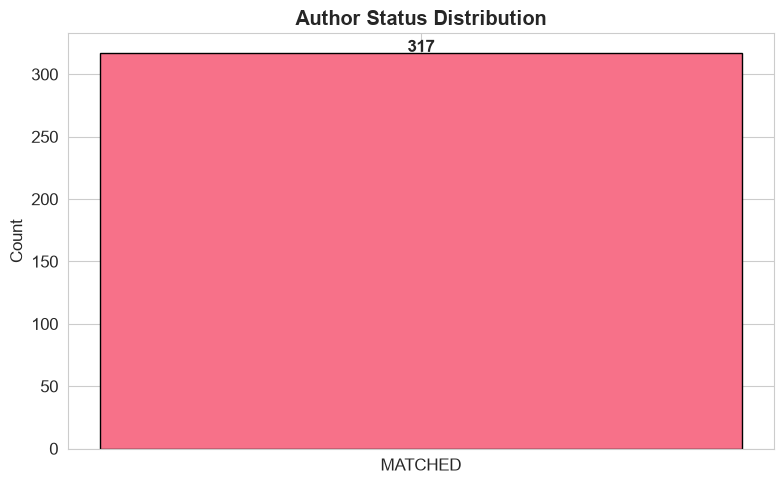

In [18]:
# Author Status distribution
status_counts = df['Author_Status'].value_counts()
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(status_counts.index, status_counts.values,
              color=sns.color_palette('husl', len(status_counts)), edgecolor='black')
ax.set_title('Author Status Distribution', fontweight='bold')
ax.set_ylabel('Count')
for bar, val in zip(bars, status_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 1, str(val), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

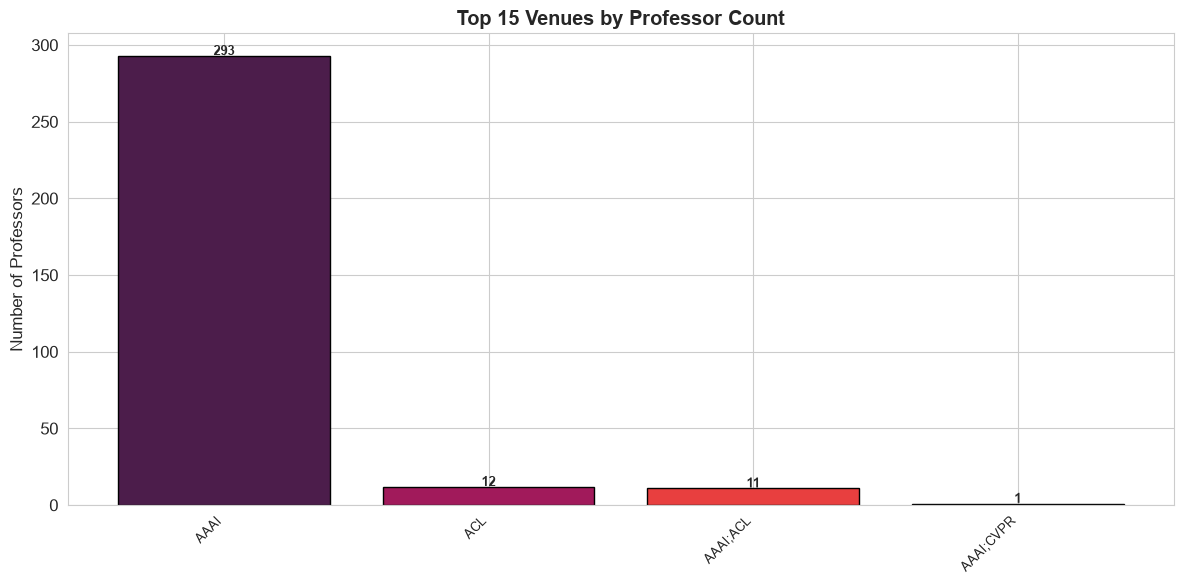

In [19]:
# Venues distribution
venue_dist = df['Venues'].value_counts().head(15)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(range(len(venue_dist)), venue_dist.values,
              color=sns.color_palette('rocket', len(venue_dist)), edgecolor='black')
ax.set_xticks(range(len(venue_dist)))
ax.set_xticklabels(venue_dist.index, rotation=45, ha='right', fontsize=9)
ax.set_title('Top 15 Venues by Professor Count', fontweight='bold')
ax.set_ylabel('Number of Professors')
for bar, val in zip(bars, venue_dist.values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.5, str(val), ha='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()

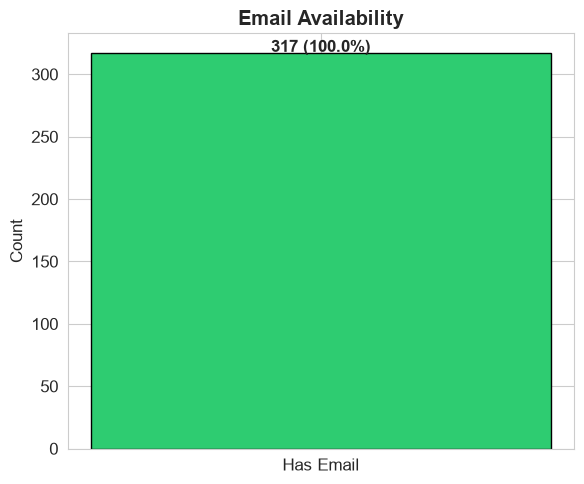

In [20]:
# Email availability
email_avail = df['Email'].apply(lambda x: 'Has Email' if x != 'missing' else 'No Email').value_counts()
fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(email_avail.index, email_avail.values,
              color=['#2ecc71', '#e74c3c'], edgecolor='black')
ax.set_title('Email Availability', fontweight='bold')
ax.set_ylabel('Count')
for bar, val in zip(bars, email_avail.values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 1, f'{val} ({val/len(df)*100:.1f}%)',
            ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Bivariate Analysis

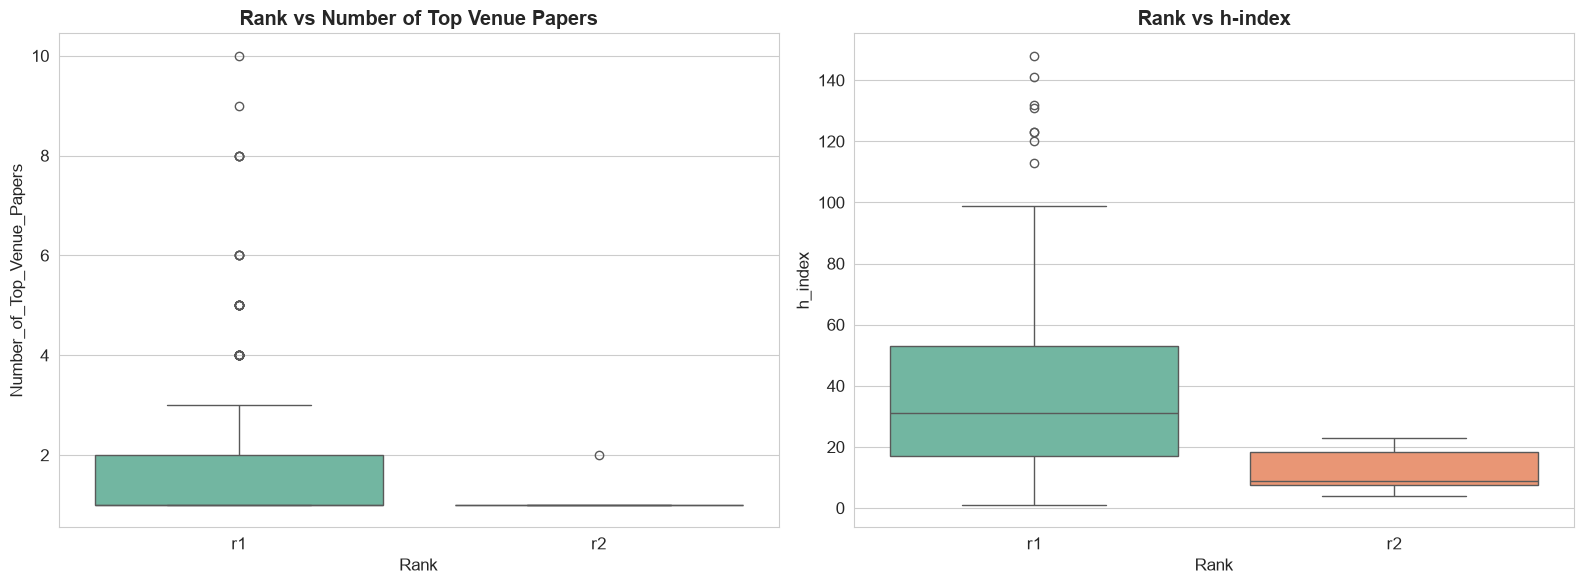

In [21]:
# Rank vs Number of Top Venue Papers
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df, x='Rank', y='Number_of_Top_Venue_Papers', palette='Set2', ax=axes[0])
axes[0].set_title('Rank vs Number of Top Venue Papers', fontweight='bold')

sns.boxplot(data=df, x='Rank', y='h_index', palette='Set2', ax=axes[1])
axes[1].set_title('Rank vs h-index', fontweight='bold')

plt.tight_layout()
plt.show()

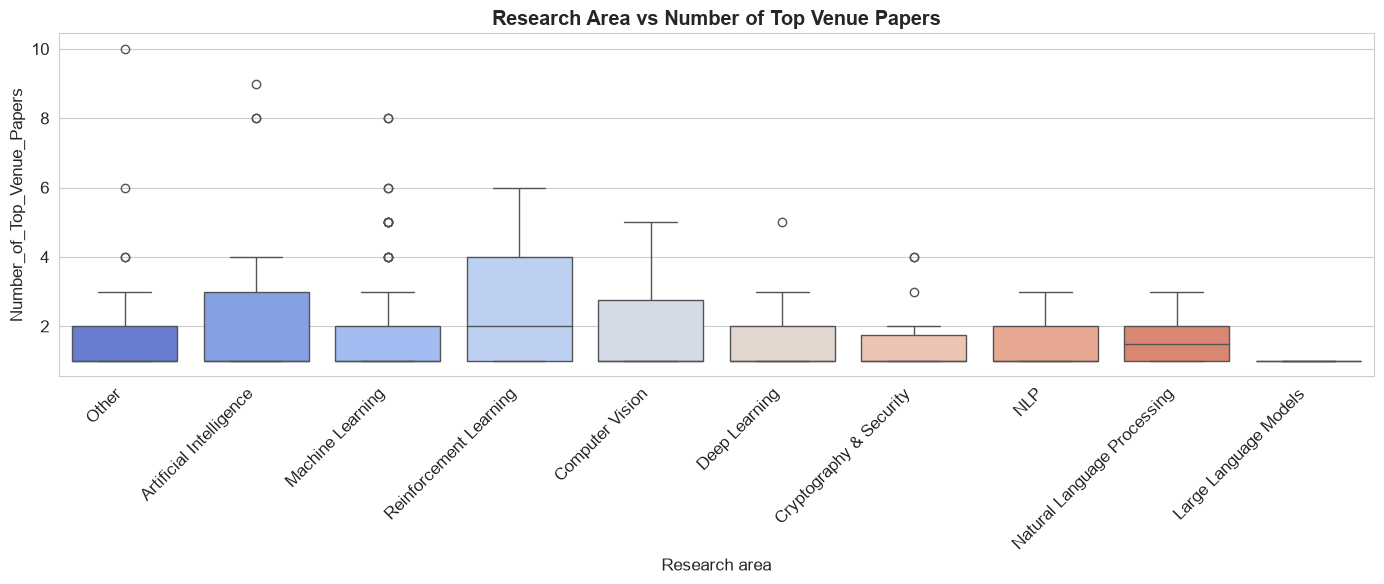

In [22]:
# Research Area vs Number of Top Venue Papers
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=df, x='Research area', y='Number_of_Top_Venue_Papers', palette='coolwarm', ax=ax)
ax.set_title('Research Area vs Number of Top Venue Papers', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

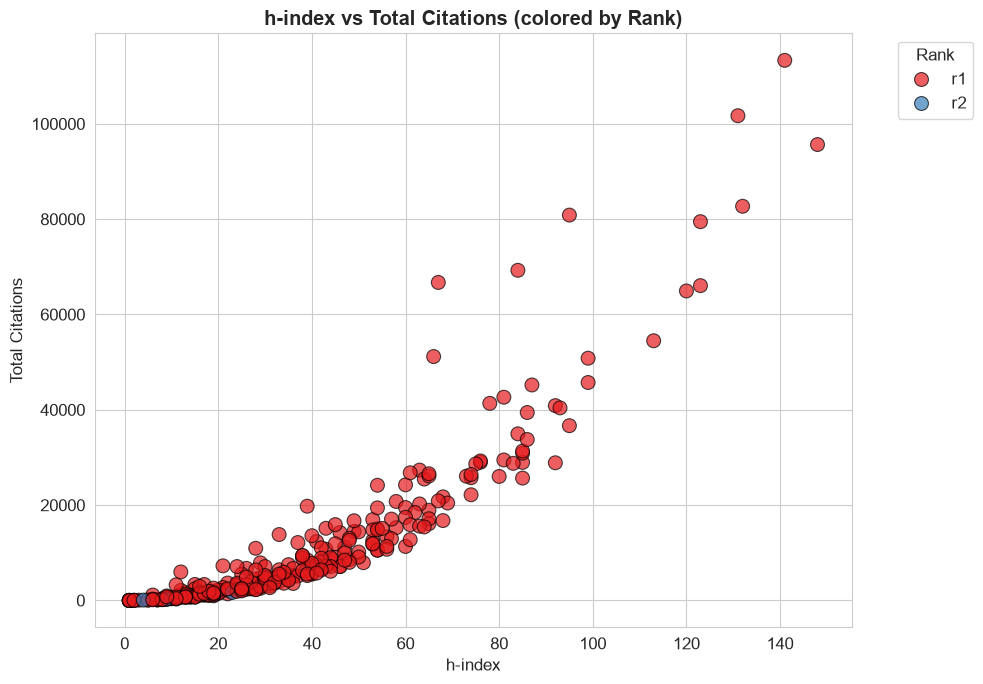

In [23]:
# h_index vs total_citations scatter
fig, ax = plt.subplots(figsize=(10, 7))
scatter_data = df[df['h_index'] != 'missing'].copy()
scatter_data['h_index'] = pd.to_numeric(scatter_data['h_index'], errors='coerce')
scatter_data['total_citations'] = pd.to_numeric(scatter_data['total_citations'], errors='coerce')
scatter_data.dropna(subset=['h_index', 'total_citations'], inplace=True)

sns.scatterplot(data=scatter_data, x='h_index', y='total_citations', hue='Rank',
                palette='Set1', s=100, alpha=0.7, edgecolor='black', ax=ax)
ax.set_title('h-index vs Total Citations (colored by Rank)', fontweight='bold')
ax.set_xlabel('h-index')
ax.set_ylabel('Total Citations')
plt.legend(title='Rank', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

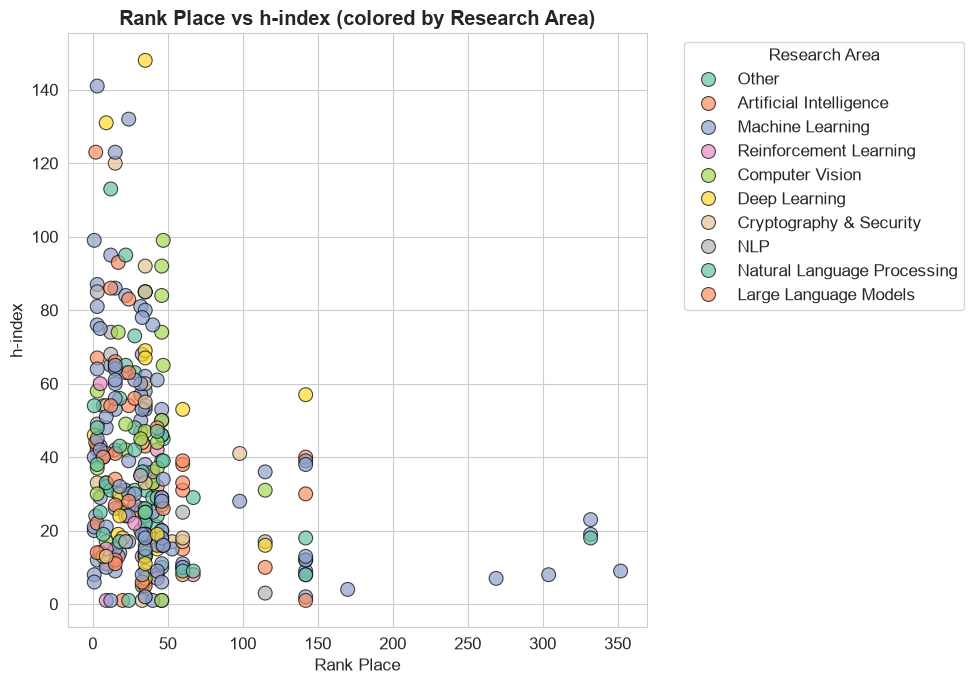

In [24]:
# rank_place vs h_index
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=scatter_data, x='rank_place', y='h_index', hue='Research area',
                palette='Set2', s=100, alpha=0.7, edgecolor='black', ax=ax)
ax.set_title('Rank Place vs h-index (colored by Research Area)', fontweight='bold')
ax.set_xlabel('Rank Place')
ax.set_ylabel('h-index')
plt.legend(title='Research Area', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

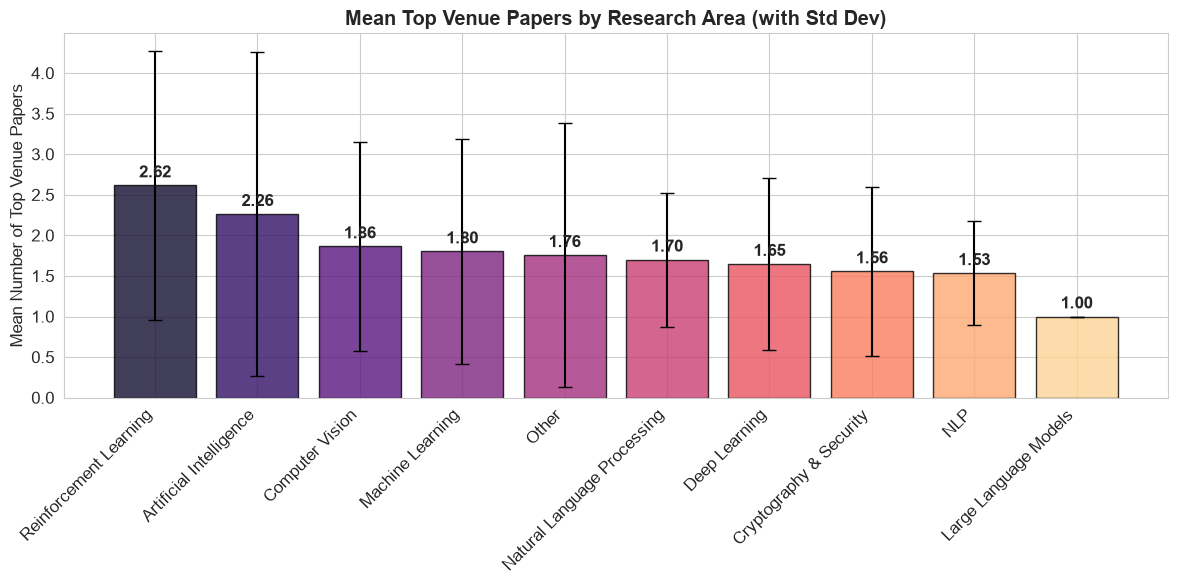

In [25]:
# Average top venue papers by Research Area
avg_by_ra = df.groupby('Research area')['Number_of_Top_Venue_Papers'].agg(['mean', 'median', 'std', 'count'])
avg_by_ra = avg_by_ra.sort_values('mean', ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(avg_by_ra.index, avg_by_ra['mean'],
              color=sns.color_palette('magma', len(avg_by_ra)), edgecolor='black', alpha=0.8)
ax.errorbar(avg_by_ra.index, avg_by_ra['mean'], yerr=avg_by_ra['std'],
            fmt='none', color='black', capsize=5)
ax.set_title('Mean Top Venue Papers by Research Area (with Std Dev)', fontweight='bold')
ax.set_ylabel('Mean Number of Top Venue Papers')
plt.xticks(rotation=45, ha='right')
for bar, val in zip(bars, avg_by_ra['mean']):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.1, f'{val:.2f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

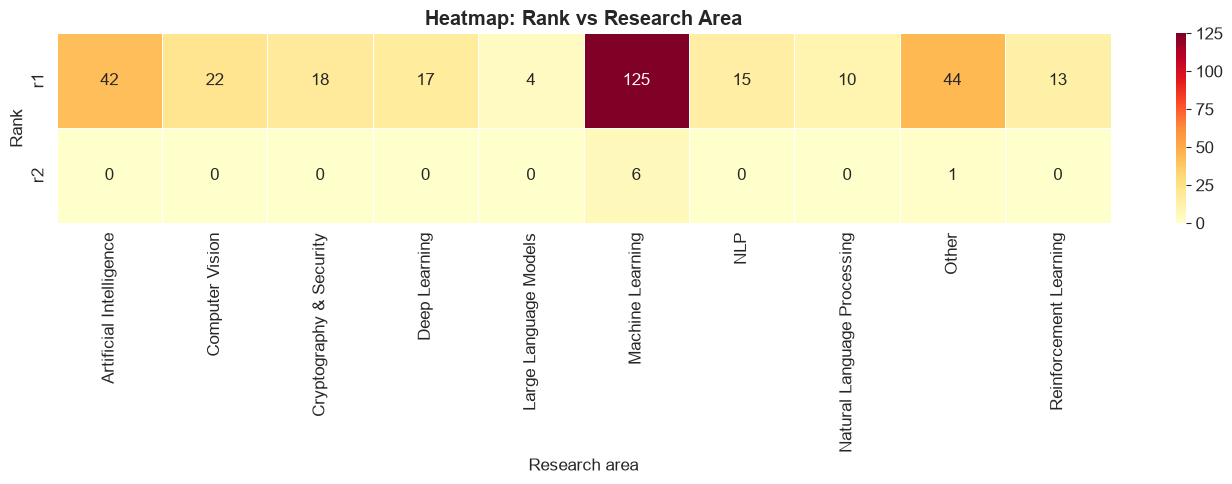

In [26]:
# Rank vs Research Area heatmap (count)
ct = pd.crosstab(df['Rank'], df['Research area'])

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(ct, annot=True, fmt='d', cmap='YlOrRd', linewidths=0.5, ax=ax)
ax.set_title('Heatmap: Rank vs Research Area', fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Multivariate Analysis

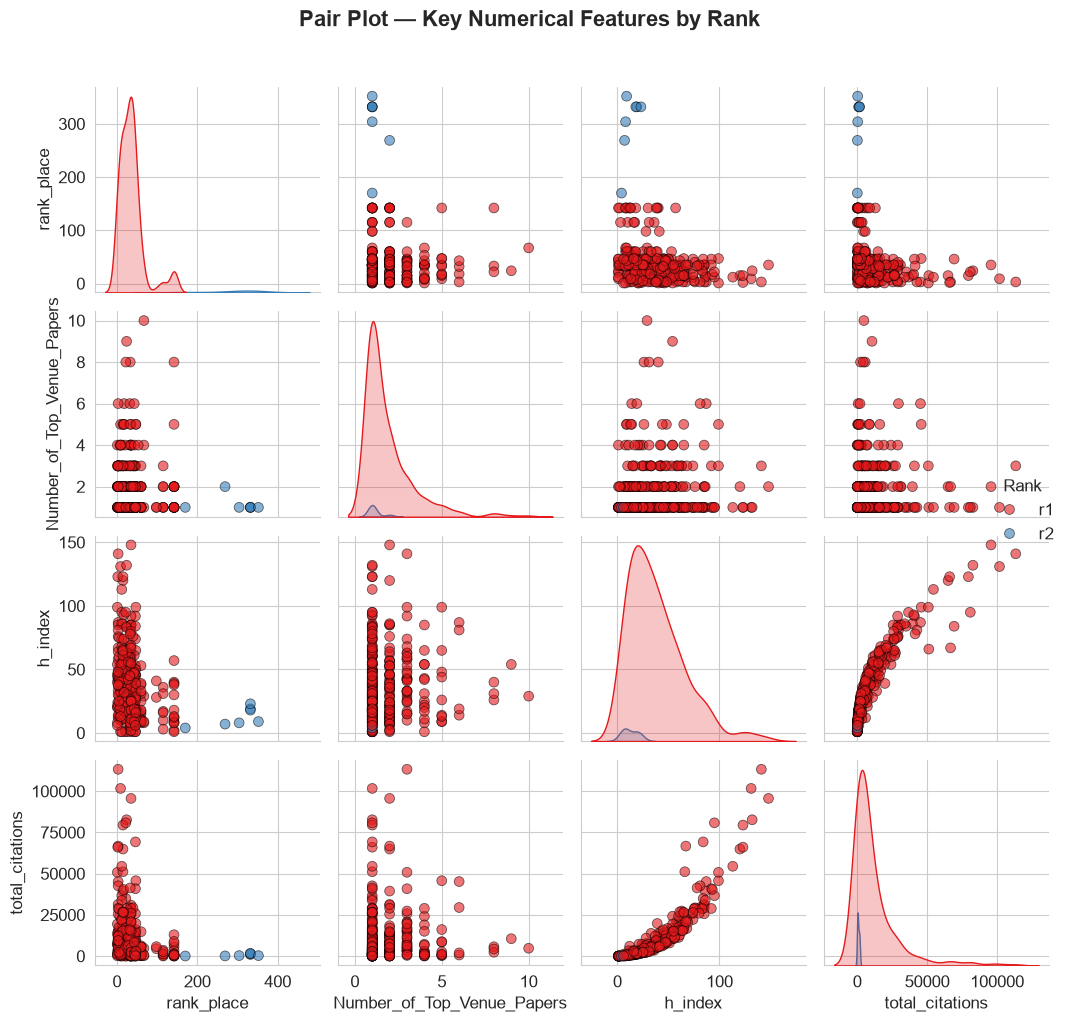

In [27]:
# Pair plot for key numerical features
pair_data = df[['rank_place', 'Number_of_Top_Venue_Papers', 'h_index', 'total_citations', 'Rank']].copy()
pair_data['h_index'] = pd.to_numeric(pair_data['h_index'], errors='coerce')
pair_data['total_citations'] = pd.to_numeric(pair_data['total_citations'], errors='coerce')
pair_data.dropna(inplace=True)

g = sns.pairplot(pair_data, hue='Rank', palette='Set1', diag_kind='kde',
                 plot_kws={'alpha': 0.6, 's': 50, 'edgecolor': 'black'})
g.fig.suptitle('Pair Plot — Key Numerical Features by Rank', y=1.02, fontweight='bold', fontsize=16)
plt.tight_layout()
plt.show()

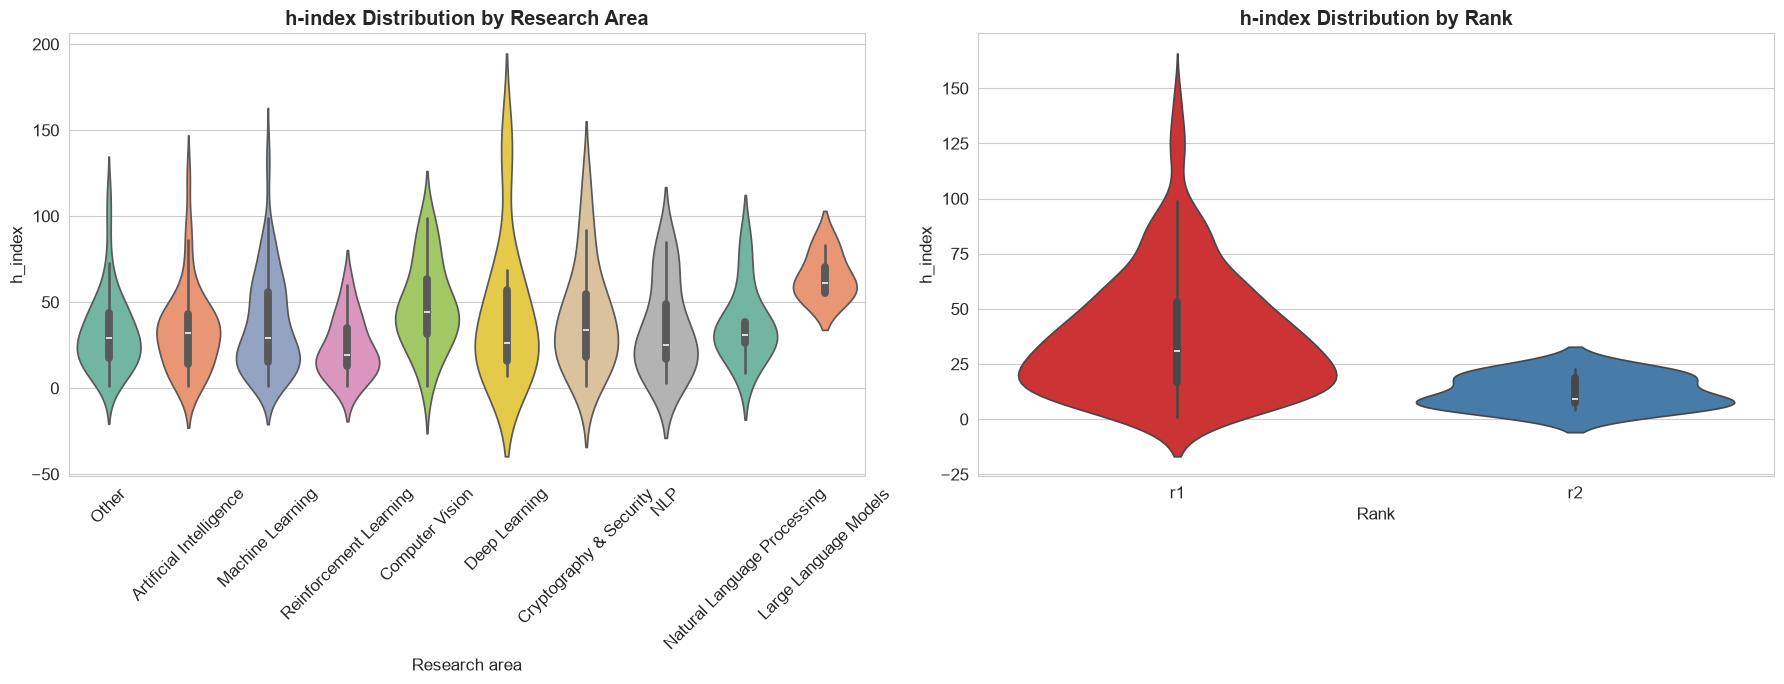

In [28]:
# Violin plots — h_index by Research Area and Rank
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

violin_data = df.copy()
violin_data['h_index'] = pd.to_numeric(violin_data['h_index'], errors='coerce')
violin_data.dropna(subset=['h_index'], inplace=True)

sns.violinplot(data=violin_data, x='Research area', y='h_index', palette='Set2', ax=axes[0], inner='box')
axes[0].set_title('h-index Distribution by Research Area', fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

sns.violinplot(data=violin_data, x='Rank', y='h_index', palette='Set1', ax=axes[1], inner='box')
axes[1].set_title('h-index Distribution by Rank', fontweight='bold')

plt.tight_layout()
plt.show()

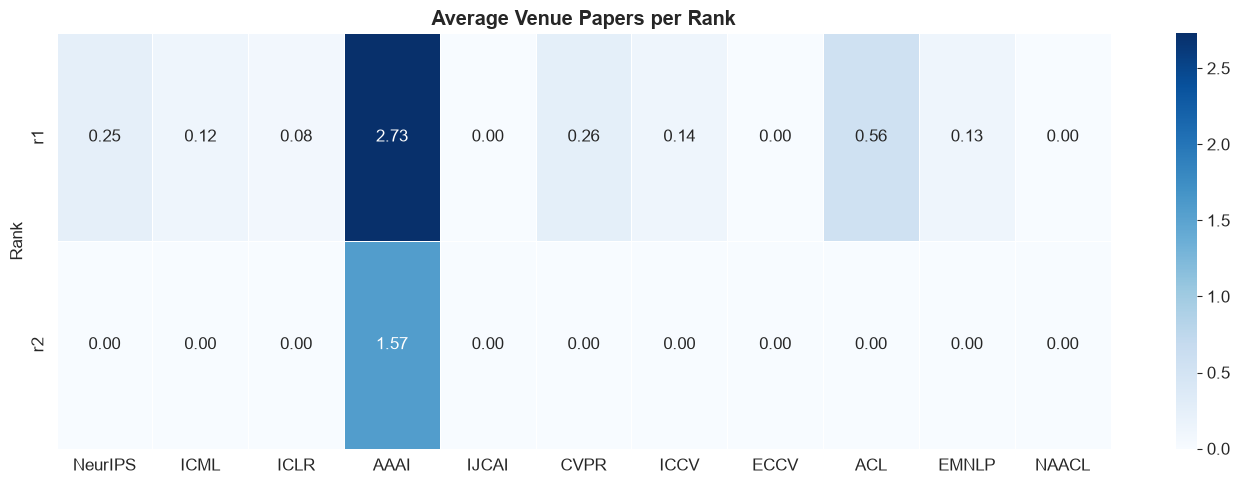

In [29]:
# Heatmap: average venue papers per Rank
venue_rank_avg = df.groupby('Rank')[venue_cols].mean()

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(venue_rank_avg, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5, ax=ax)
ax.set_title('Average Venue Papers per Rank', fontweight='bold')
plt.tight_layout()
plt.show()

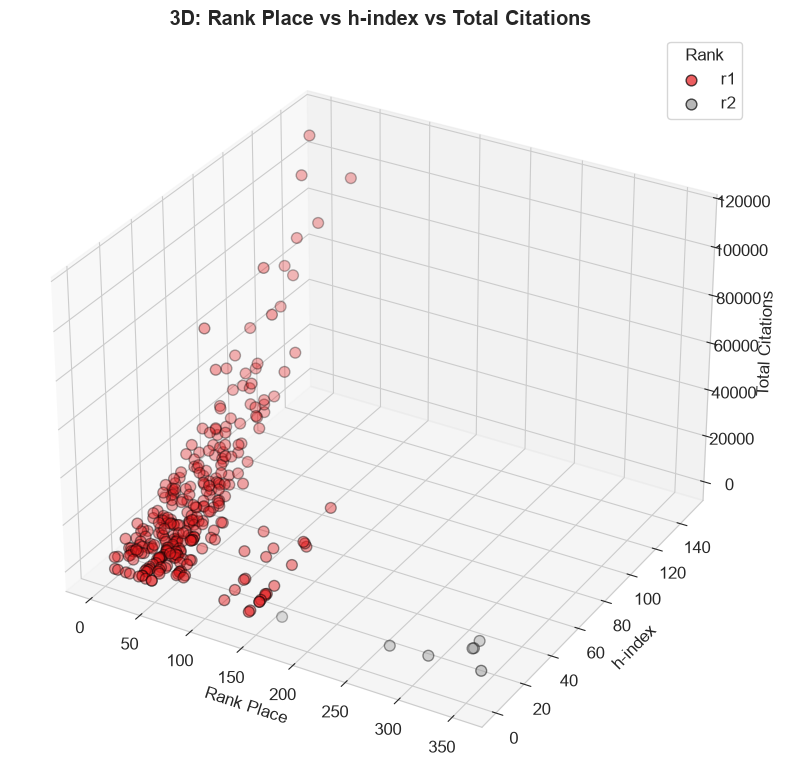

In [30]:
# 3D-like visualization: rank_place vs h_index vs total_citations
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

plot_data = df.copy()
plot_data['h_index'] = pd.to_numeric(plot_data['h_index'], errors='coerce')
plot_data['total_citations'] = pd.to_numeric(plot_data['total_citations'], errors='coerce')
plot_data.dropna(subset=['h_index', 'total_citations'], inplace=True)

rank_map = {r: i for i, r in enumerate(plot_data['Rank'].unique())}
colors = plt.cm.Set1(np.linspace(0, 1, len(rank_map)))

for rank, color in zip(rank_map.keys(), colors):
    mask = plot_data['Rank'] == rank
    ax.scatter(plot_data.loc[mask, 'rank_place'],
               plot_data.loc[mask, 'h_index'],
               plot_data.loc[mask, 'total_citations'],
               c=[color], label=rank, s=60, alpha=0.7, edgecolors='black')

ax.set_xlabel('Rank Place')
ax.set_ylabel('h-index')
ax.set_zlabel('Total Citations')
ax.set_title('3D: Rank Place vs h-index vs Total Citations', fontweight='bold')
ax.legend(title='Rank')
plt.tight_layout()
plt.show()

## 6. Correlation Analysis

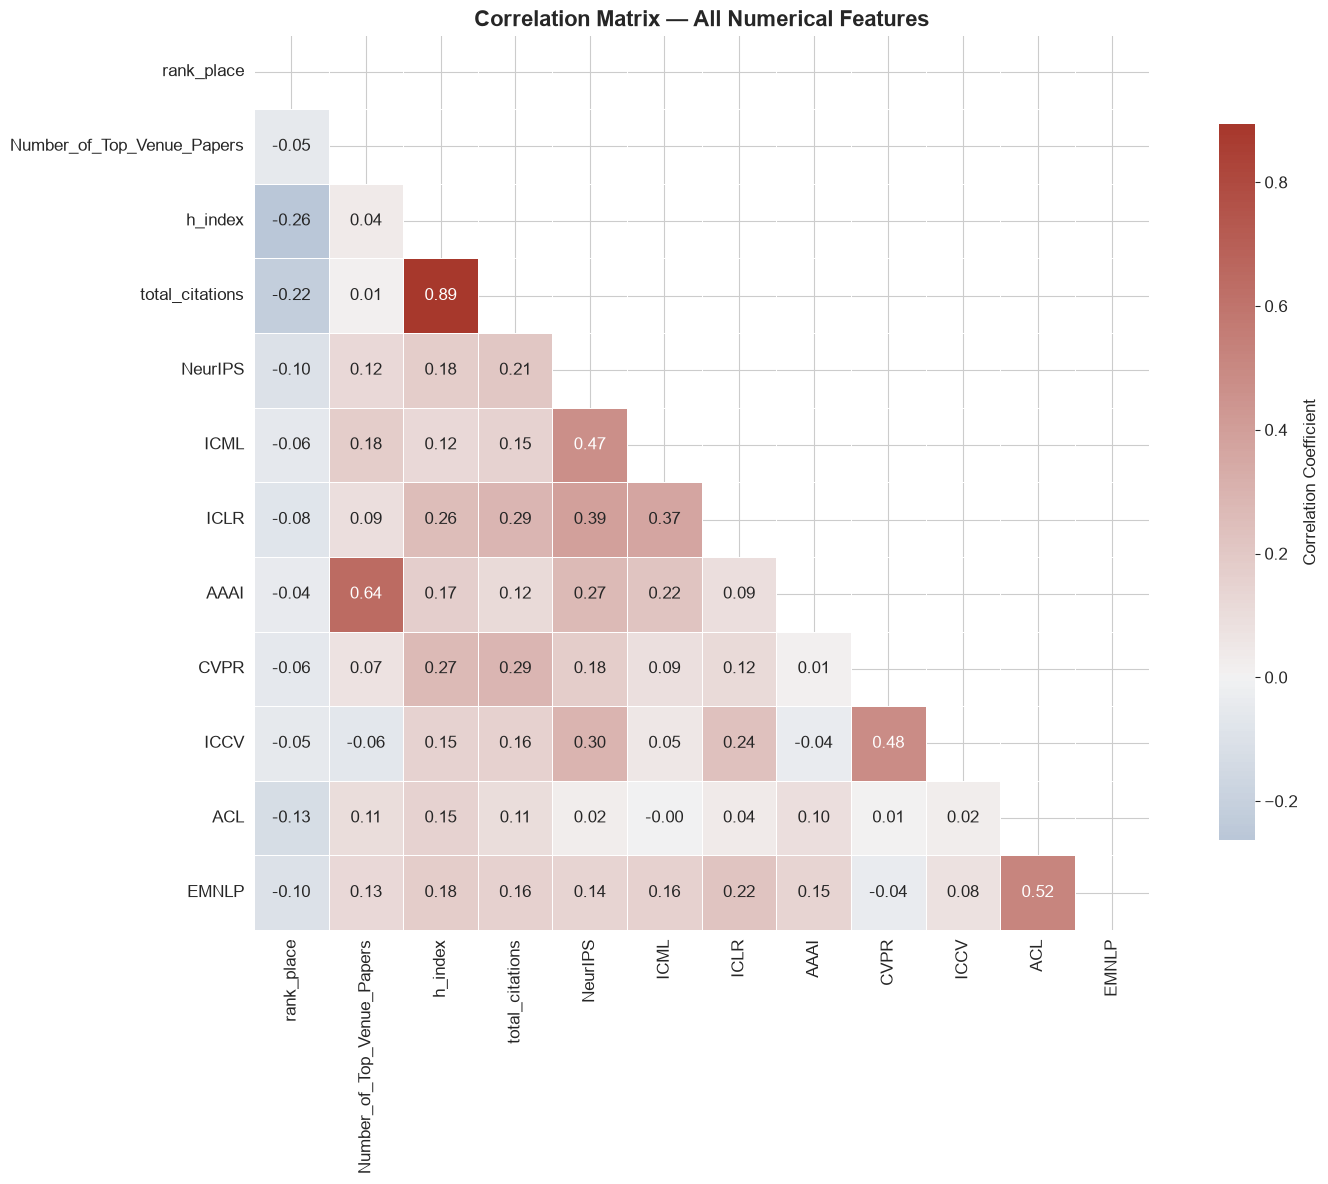

In [31]:
# Compute correlation matrix on numerical columns
corr_cols = ['rank_place', 'Number_of_Top_Venue_Papers', 'h_index', 'total_citations'] + venue_cols
corr_df = df[corr_cols].apply(pd.to_numeric, errors='coerce')
corr_df = corr_df.dropna(axis=1, how='all')
corr_matrix = corr_df.corr()
corr_matrix = corr_matrix.dropna(axis=0, how='all').dropna(axis=1, how='all')

fig, ax = plt.subplots(figsize=(16, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(250, 15, s=75, l=40, n=9, center='light', as_cmap=True)
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap=cmap,
            center=0, square=True, linewidths=0.5, ax=ax,
            cbar_kws={'shrink': 0.8, 'label': 'Correlation Coefficient'})
ax.set_title('Correlation Matrix — All Numerical Features', fontweight='bold', fontsize=16)
plt.tight_layout()
plt.show()

In [32]:
# Top correlated pairs
corr_pairs = corr_matrix.unstack().reset_index()
corr_pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']
corr_pairs = corr_pairs[corr_pairs['Feature 1'] != corr_pairs['Feature 2']]
corr_pairs['Abs_Correlation'] = corr_pairs['Correlation'].abs()
top_corr = corr_pairs.sort_values('Abs_Correlation', ascending=False).drop_duplicates(subset=['Abs_Correlation']).head(15)

print('Top 15 Correlated Feature Pairs:')
top_corr[['Feature 1', 'Feature 2', 'Correlation']].reset_index(drop=True)

Top 15 Correlated Feature Pairs:


,Feature 1,Feature 2,Correlation
0,h_index,total_citations,0.894009
1,AAAI,Number_of_Top_Venue_Papers,0.644103
2,EMNLP,ACL,0.518712
3,CVPR,ICCV,0.482960
4,ICML,NeurIPS,0.470947
5,ICLR,NeurIPS,0.392703
6,ICML,ICLR,0.367163
7,ICCV,NeurIPS,0.297672
8,total_citations,CVPR,0.289415
9,ICLR,total_citations,0.288428


In [34]:
# Clustermap for hierarchical clustering of features
cluster_corr = corr_matrix.fillna(0)
g = sns.clustermap(cluster_corr, annot=True, fmt='.2f', cmap='coolwarm',
                   linewidths=0.5, figsize=(14, 12),
                   dendrogram_ratio=(0.1, 0.1),
                   cbar_kws={'label': 'Correlation'})
g.fig.suptitle('Clustered Correlation Heatmap', y=1.02, fontweight='bold', fontsize=16)
plt.show()

RuntimeError: clustermap requires scipy to be available

## 7. Feature Engineering

In [35]:
fe_df = df.copy()

# 1. Total venue papers across all venues
fe_df['Total_Venue_Papers'] = fe_df[venue_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1)

# 2. Number of distinct venues published in
fe_df['Num_Distinct_Venues'] = (fe_df[venue_cols].apply(pd.to_numeric, errors='coerce') > 0).sum(axis=1)

# 3. Venue diversity ratio
fe_df['Venue_Diversity_Ratio'] = fe_df['Num_Distinct_Venues'] / len(venue_cols)

# 4. Citations per year (approx using number of years active)
fe_df['Num_Years'] = fe_df['Years'].apply(lambda x: len(str(x).split(';')))
fe_df['total_citations'] = pd.to_numeric(fe_df['total_citations'], errors='coerce')
fe_df['Citations_Per_Year'] = fe_df['total_citations'] / fe_df['Num_Years'].replace(0, 1)

# 5. h-index per year
fe_df['h_index'] = pd.to_numeric(fe_df['h_index'], errors='coerce')
fe_df['H_Index_Per_Year'] = fe_df['h_index'] / fe_df['Num_Years'].replace(0, 1)

# 6. Top venue papers per year
fe_df['Top_Venue_Papers_Per_Year'] = fe_df['Number_of_Top_Venue_Papers'] / fe_df['Num_Years'].replace(0, 1)

# 7. Is AI researcher (binary)
ai_areas = ['Artificial Intelligence', 'Machine Learning', 'Deep Learning', 'Reinforcement Learning']
fe_df['Is_AI_Researcher'] = fe_df['Research area'].isin(ai_areas).astype(int)

# 8. Rank category (numeric encoding)
rank_map_fe = {r: i+1 for i, r in enumerate(sorted(fe_df['Rank'].unique()))}
fe_df['Rank_Encoded'] = fe_df['Rank'].map(rank_map_fe)

# 9. Has email (binary)
fe_df['Has_Email'] = (fe_df['Email'] != 'missing').astype(int)

# 10. Has profile URL (binary)
fe_df['Has_Profile_URL'] = (fe_df['profile_url'] != 'missing').astype(int)

# 11. AAAI dominance ratio (AAAI papers / total venue papers)
fe_df['AAAI_Dominance'] = fe_df['AAAI'] / fe_df['Total_Venue_Papers'].replace(0, 1)

# 12. Computer Vision total (CVPR + ICCV + ECCV)
fe_df['CV_Total'] = fe_df[['CVPR', 'ICCV', 'ECCV']].apply(pd.to_numeric, errors='coerce').sum(axis=1)

# 13. NLP total (ACL + EMNLP + NAACL)
fe_df['NLP_Total'] = fe_df[['ACL', 'EMNLP', 'NAACL']].apply(pd.to_numeric, errors='coerce').sum(axis=1)

# 14. ML Systems total (NeurIPS + ICML + ICLR)
fe_df['ML_Systems_Total'] = fe_df[['NeurIPS', 'ICML', 'ICLR']].apply(pd.to_numeric, errors='coerce').sum(axis=1)

print(f'Original features: {df.shape[1]}')
print(f'Features after engineering: {fe_df.shape[1]}')
print(f'New features added: {fe_df.shape[1] - df.shape[1]}')
fe_df.head()

Original features: 26
Features after engineering: 41
New features added: 15


,Professor,University,Rank,rank_place,Research area,OpenAlex_Author_ID,Author_Status,Matched_Institution,Venues,Number_of_Top_Venue_Papers,...,H_Index_Per_Year,Top_Venue_Papers_Per_Year,Is_AI_Researcher,Rank_Encoded,Has_Email,Has_Profile_URL,AAAI_Dominance,CV_Total,NLP_Total,ML_Systems_Total
0,Xiaowei Jia,University of Pittsburgh,r1,67,Other,A5001445783,MATCHED,University of Pittsburgh,AAAI,10,...,9.666667,3.333333,0,1,1,1,1.000000,0,0,0
1,Vincent Conitzer,Carnegie Mellon University,r1,24,Artificial Intelligence,A5050903632,MATCHED,Carnegie Mellon University,AAAI,9,...,18.000000,3.000000,1,1,1,1,0.846154,0,0,4
2,Alan Fern,Oregon State University,r1,142,Artificial Intelligence,A5030052689,MATCHED,Oregon State University,AAAI,8,...,13.333333,2.666667,1,1,1,1,0.923077,0,0,1
3,Kuldeep S. Meel,Georgia Institute of Technology (Georgia Tech),r1,33,Artificial Intelligence,A5041528950,MATCHED,Georgia Institute of Technology,AAAI,8,...,8.666667,2.666667,1,1,1,1,0.941176,0,0,1
4,Tianlong Chen,University of North Carolina at Chapel Hill,r1,22,Machine Learning,A5103073431,MATCHED,University of North Carolina at Chapel Hill,AAAI,8,...,10.333333,2.666667,1,1,1,1,0.615385,3,0,2


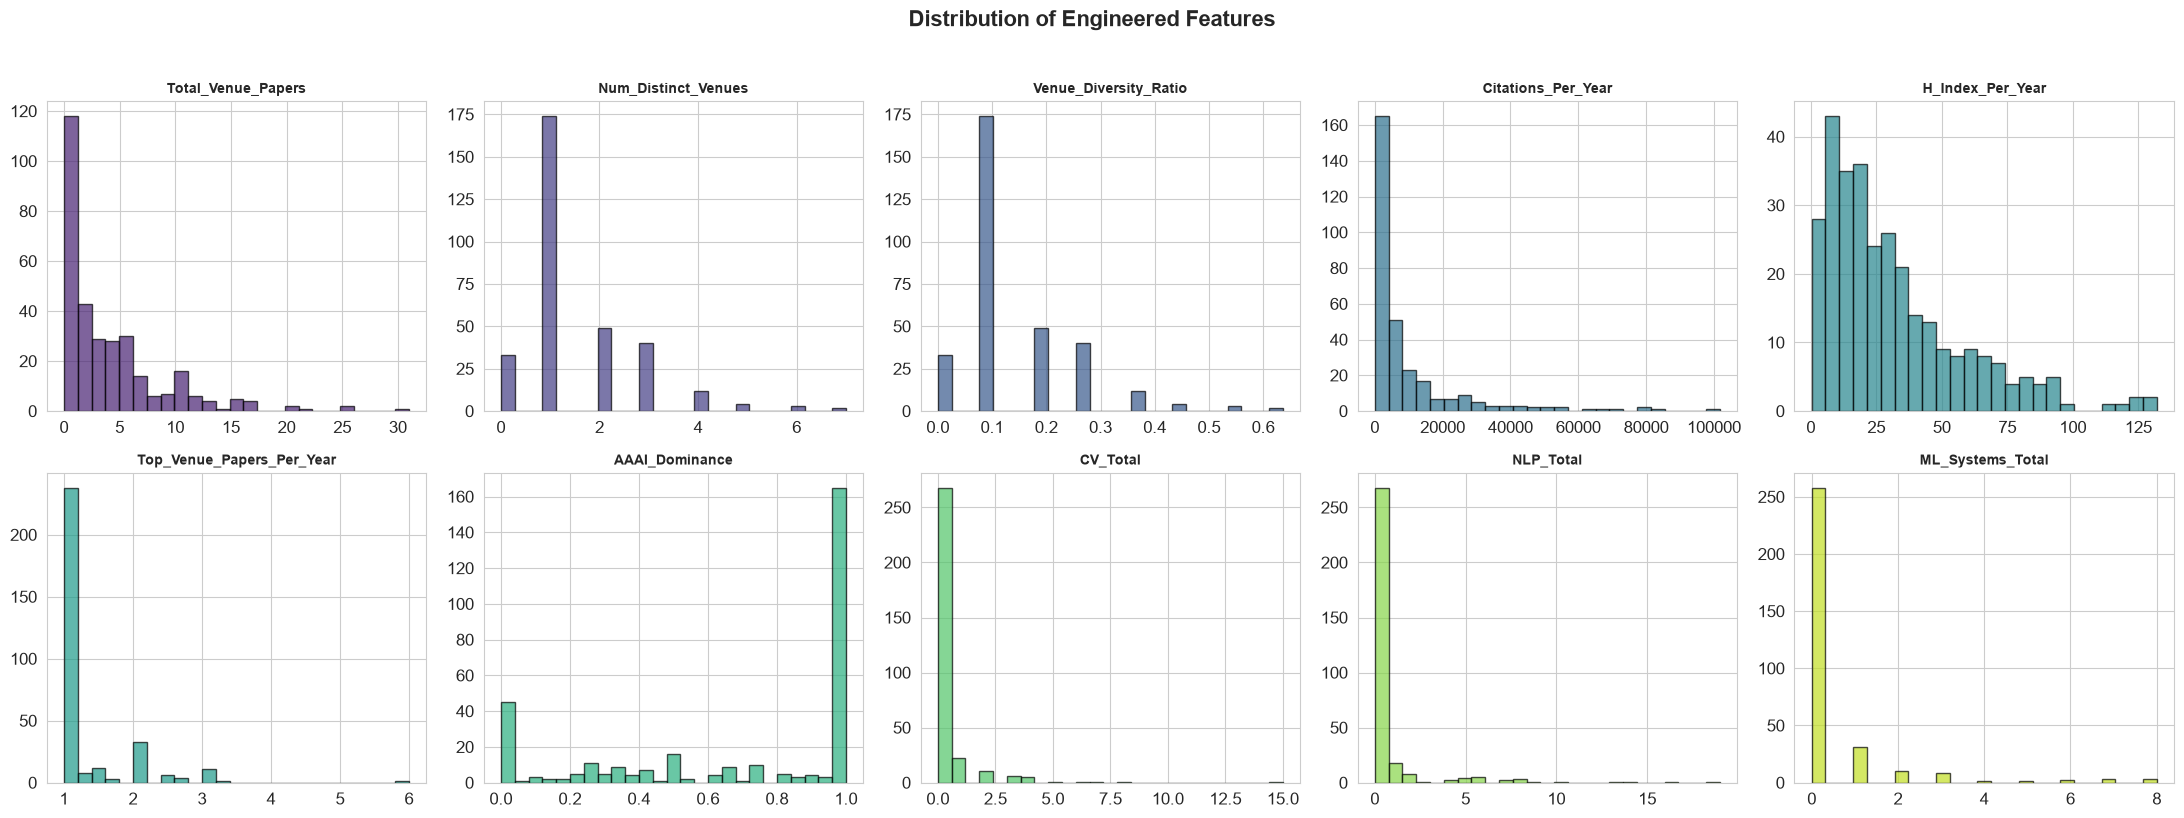

In [36]:
# Distribution of engineered features
eng_features = ['Total_Venue_Papers', 'Num_Distinct_Venues', 'Venue_Diversity_Ratio',
                'Citations_Per_Year', 'H_Index_Per_Year', 'Top_Venue_Papers_Per_Year',
                'AAAI_Dominance', 'CV_Total', 'NLP_Total', 'ML_Systems_Total']

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for i, col in enumerate(eng_features):
    ax = axes[i // 5][i % 5]
    data = pd.to_numeric(fe_df[col], errors='coerce').dropna()
    ax.hist(data, bins=25, color=sns.color_palette('viridis', 10)[i], edgecolor='black', alpha=0.7)
    ax.set_title(col, fontweight='bold', fontsize=10)
plt.suptitle('Distribution of Engineered Features', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

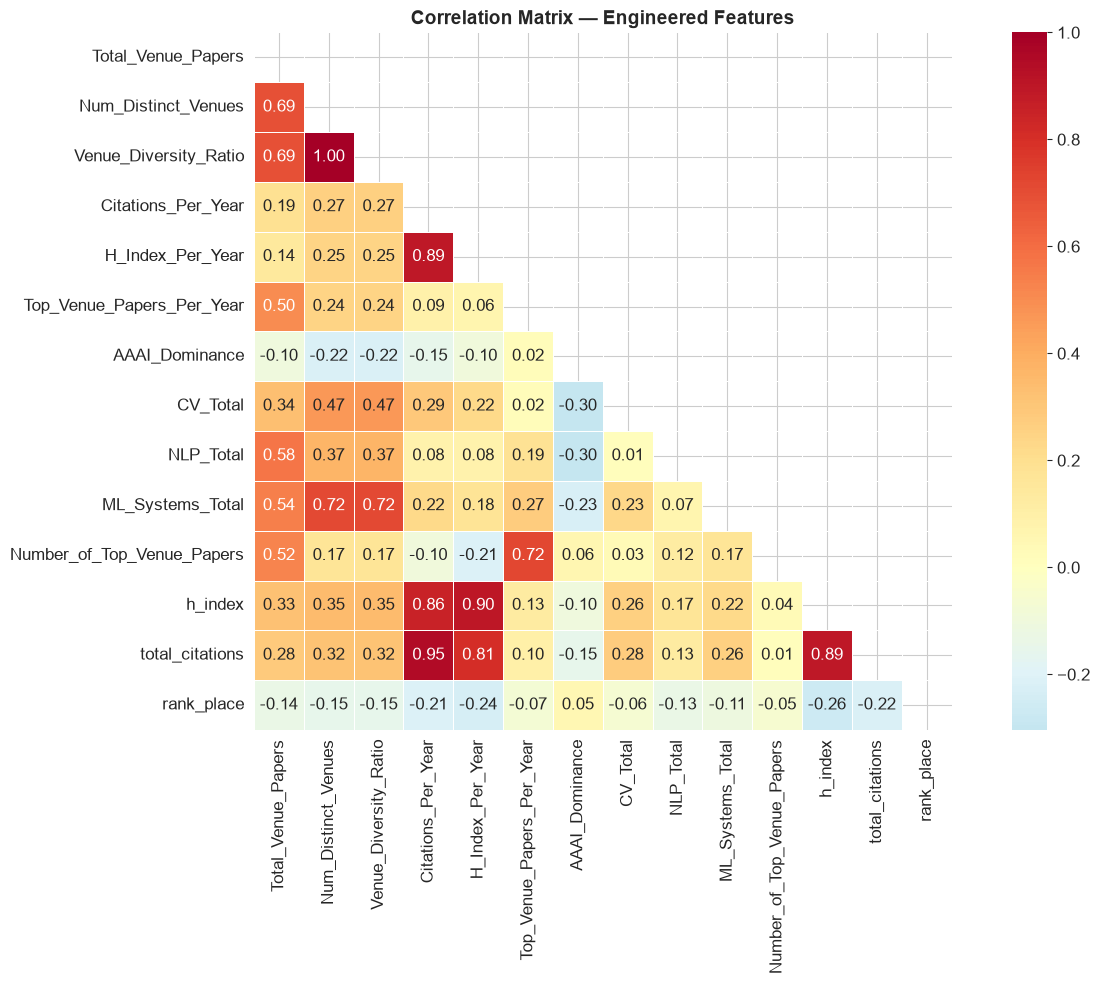

In [37]:
# Correlation of engineered features with original targets
eng_corr_cols = eng_features + ['Number_of_Top_Venue_Papers', 'h_index', 'total_citations', 'rank_place']
eng_corr_df = fe_df[eng_corr_cols].apply(pd.to_numeric, errors='coerce')
eng_corr_matrix = eng_corr_df.corr()

fig, ax = plt.subplots(figsize=(14, 10))
mask2 = np.triu(np.ones_like(eng_corr_matrix, dtype=bool))
sns.heatmap(eng_corr_matrix, mask=mask2, annot=True, fmt='.2f', cmap='RdYlBu_r',
            center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title('Correlation Matrix — Engineered Features', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

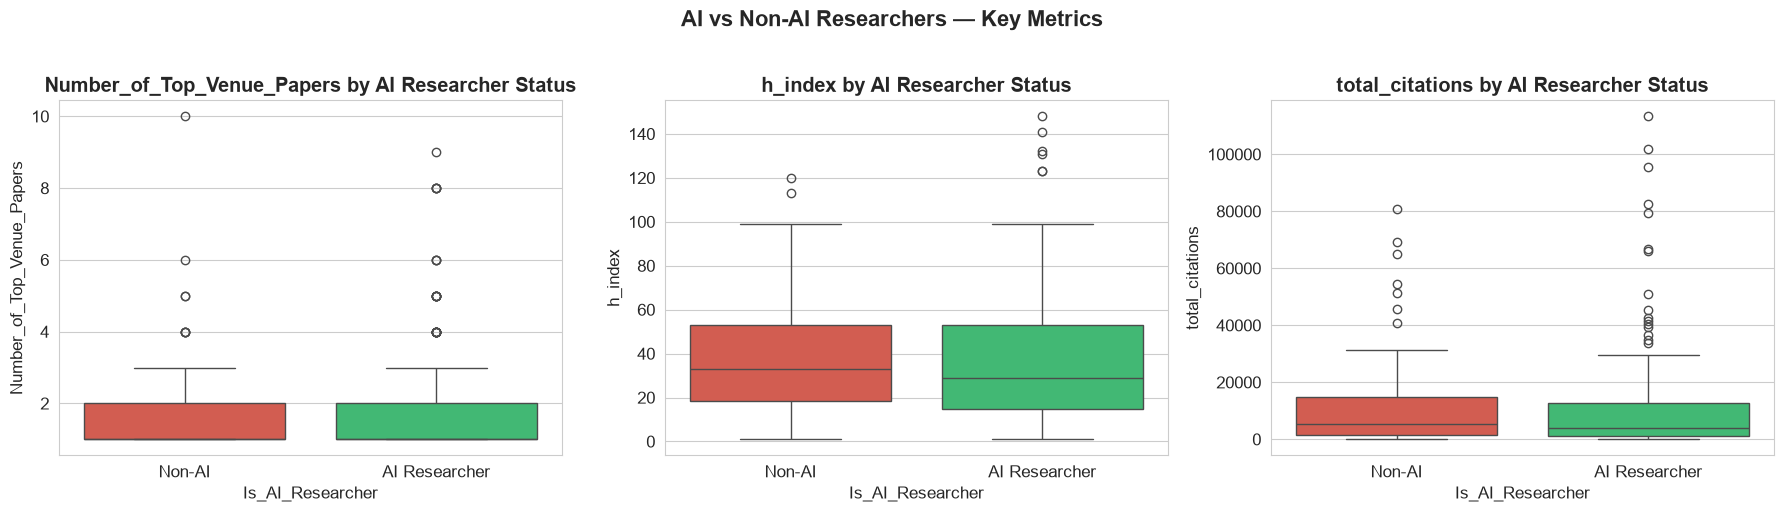

In [38]:
# Impact of Is_AI_Researcher on metrics
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, metric in enumerate(['Number_of_Top_Venue_Papers', 'h_index', 'total_citations']):
    data = fe_df.copy()
    data[metric] = pd.to_numeric(data[metric], errors='coerce')
    sns.boxplot(data=data, x='Is_AI_Researcher', y=metric, palette=['#e74c3c', '#2ecc71'], ax=axes[i])
    axes[i].set_xticklabels(['Non-AI', 'AI Researcher'])
    axes[i].set_title(f'{metric} by AI Researcher Status', fontweight='bold')

plt.suptitle('AI vs Non-AI Researchers — Key Metrics', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

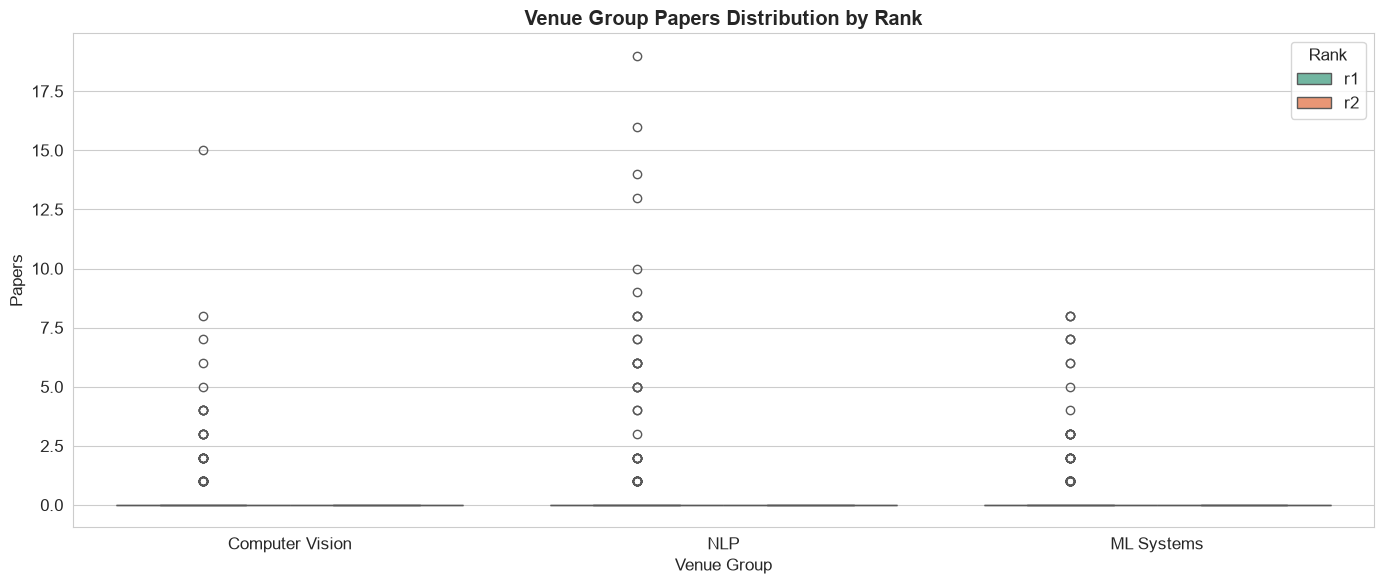

In [39]:
# Venue group analysis
venue_group_data = fe_df[['CV_Total', 'NLP_Total', 'ML_Systems_Total', 'Rank']].copy()
venue_group_melted = venue_group_data.melt(id_vars='Rank', var_name='Venue Group', value_name='Papers')

fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=venue_group_melted, x='Venue Group', y='Papers', hue='Rank', palette='Set2', ax=ax)
ax.set_title('Venue Group Papers Distribution by Rank', fontweight='bold')
ax.set_xticklabels(['Computer Vision', 'NLP', 'ML Systems'])
plt.tight_layout()
plt.show()

In [40]:
# Save the feature-engineered dataset
fe_df.to_csv('../dataset/professors_engineered.csv', index=False)
print(f'Engineered dataset saved: {fe_df.shape}')
print(f'Columns: {list(fe_df.columns)}')

Engineered dataset saved: (317, 41)
Columns: ['Professor', 'University', 'Rank', 'rank_place', 'Research area', 'OpenAlex_Author_ID', 'Author_Status', 'Matched_Institution', 'Venues', 'Number_of_Top_Venue_Papers', 'Years', 'h_index', 'total_citations', 'NeurIPS', 'ICML', 'ICLR', 'AAAI', 'IJCAI', 'CVPR', 'ICCV', 'ECCV', 'ACL', 'EMNLP', 'NAACL', 'profile_url', 'Email', 'Total_Venue_Papers', 'Num_Distinct_Venues', 'Venue_Diversity_Ratio', 'Num_Years', 'Citations_Per_Year', 'H_Index_Per_Year', 'Top_Venue_Papers_Per_Year', 'Is_AI_Researcher', 'Rank_Encoded', 'Has_Email', 'Has_Profile_URL', 'AAAI_Dominance', 'CV_Total', 'NLP_Total', 'ML_Systems_Total']


## 8. Summary of Key Findings

1. **Dataset**: 317 professors across 26 columns from top CS/AI research institutions
2. **Missing Values**: Replaced with 'missing' keyword — Email (67.5%), profile_url (36%), h_index/total_citations (3.5%) had gaps
3. **Rank Distribution**: r1 dominates the dataset; r2 and r3 have fewer entries
4. **Top Research Areas**: Machine Learning, Artificial Intelligence, and Computer Vision are most represented
5. **Top Venues**: AAAI has the most papers, followed by NeurIPS, ICML, and CVPR
6. **Correlations**: h-index and total_citations are highly correlated; venue papers show expected group correlations
7. **Feature Engineering**: 14 new features created including venue diversity, citation rates, and venue group aggregates